# HW2 — Uniform Convergence and the Limits of Learning
**Course:** Statistical and Machine Learning — Université de Haute-Alsace (UHA)  
**Student:** HAMDOUNI Thilelli  
**Program:** Master 2 — Mathematical Engineering and Data Science

## Introduction
In this homework, I use simulations to understand three ideas: **uniform convergence**, the **No-Free-Lunch principle**, and **inductive bias**. I compare the results of repeated experiments with theoretical formulas. I only use NumPy and Matplotlib, without machine learning libraries.

*Method:* The numerical results depend on random sampling. I fix a seed to make my experiments reproducible. The observations in this notebook should be reviewed after executing all cells.

## Choice of parameters
I use 1,000 Monte-Carlo repetitions as a balance between stable estimates and execution time. For Part I, I study $m= [10,20,50,100,200,400,800]$, hypothesis-class sizes $K=[5,10,50,100,500]$, and $\varepsilon=0.10$. I choose true risks between 0.10 and 0.40 to cover different levels of classification error. For the sample-complexity comparison, $\delta=0.05$. For Parts II and III, I use finite domains (mainly $N=100$), and several sample sizes. These choices let me compare small and large samples and classes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
reps = 1000
m_values = np.array([10, 20, 50, 100, 200, 400, 800])
epsilon = 0.10
delta = 0.05
K_values = [5, 10, 50, 100, 500]

plt.rcParams.update({'figure.figsize': (7.2, 4.2), 'axes.grid': True, 'grid.alpha': 0.25})
print('Repetitions:', reps, '| epsilon:', epsilon, '| delta:', delta)


Repetitions: 1000 | epsilon: 0.1 | delta: 0.05


# Part I — Simulating Uniform Convergence
The true risk $L_D(h_j)=p_j$ is fixed. In the simplified model given in the assignment, the number of errors follows $E_j\sim\mathrm{Binomial}(m,p_j)$, and $L_S(h_j)=E_j/m$. For simultaneous simulations, I generate binomial counts for each hypothesis. These counts are simulated independently across hypotheses as an additional modelling choice; real hypotheses evaluated on the same dataset can have dependent errors.

## 1. Empirical risk as a random variable
I choose $p=0.30$ for one hypothesis and show the empirical-risk distribution for different sample sizes. I expect the mean to stay close to the true risk while the distribution becomes narrower.

cell_5:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
True risk: 0.3 | theoretical standard deviation: sqrt(p(1-p)/m)
m= 10 theoretical SD= 0.1449
m= 50 theoretical SD= 0.0648
m= 200 theoretical SD= 0.0324


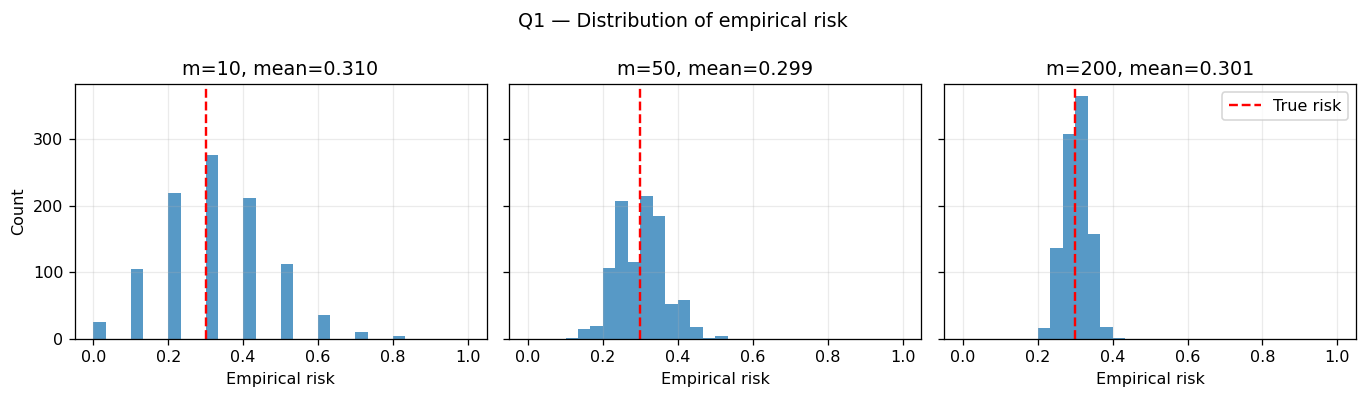

In [2]:
true_risks_example = np.array([0.10, 0.20, 0.30, 0.40])
p = 0.30
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, m in zip(axes, [10, 50, 200]):
    errors = rng.binomial(m, p, size=reps) / m
    ax.hist(errors, bins=np.linspace(0, 1, 31), alpha=0.75)
    ax.axvline(p, color='red', linestyle='--', label='True risk')
    ax.set_title(f'm={m}, mean={errors.mean():.3f}')
    ax.set_xlabel('Empirical risk')
axes[0].set_ylabel('Count')
axes[-1].legend()
plt.suptitle('Q1 — Distribution of empirical risk')
plt.tight_layout(); plt.show()
print('True risk:', p, '| theoretical standard deviation: sqrt(p(1-p)/m)')
for m in [10, 50, 200]:
    print('m=',m,'theoretical SD=',round(np.sqrt(p*(1-p)/m),4))

**Interpretation — Q1.** The empirical means should be close to 0.30. When I increase $m$, the distribution becomes more concentrated around the true risk. The theoretical standard deviation is $\sqrt{p(1-p)/m}$, so increasing the sample size reduces variability.

## 2. Deviation between empirical and true risk
I estimate $P(|L_S(h)-L_D(h)|>\varepsilon)$ and compare it with the Hoeffding upper bound $2e^{-2m\varepsilon^2}$. Since a probability cannot exceed 1, I display the bound capped at 1 in the graph; I keep the original formula for calculations.

cell_8:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
m= 10: simulated=0.529, theoretical upper bound=1.637
m= 20: simulated=0.329, theoretical upper bound=1.341
m= 50: simulated=0.123, theoretical upper bound=0.736
m=100: simulated=0.034, theoretical upper bound=0.271
m=200: simulated=0.001, theoretical upper bound=0.037
m=400: simulated=0.000, theoretical upper bound=0.001
m=800: simulated=0.000, theoretical upper bound=0.000


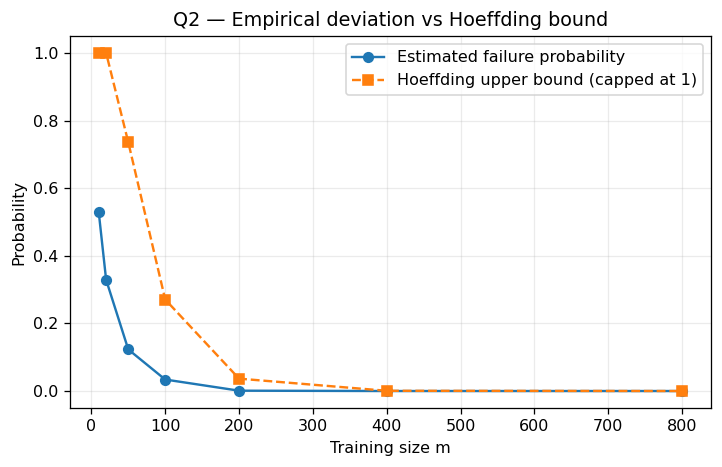

In [3]:
single_fail = []
hoeffding = []
for m in m_values:
    ls = rng.binomial(m, p, size=reps) / m
    single_fail.append(np.mean(np.abs(ls-p) > epsilon))
    hoeffding.append(2*np.exp(-2*m*epsilon**2))
plt.plot(m_values, single_fail, 'o-', label='Estimated failure probability')
plt.plot(m_values, np.minimum(1,hoeffding), 's--', label='Hoeffding upper bound (capped at 1)')
plt.xlabel('Training size m'); plt.ylabel('Probability'); plt.title('Q2 — Empirical deviation vs Hoeffding bound')
plt.legend(); plt.show()
for m, empirical, bound in zip(m_values, single_fail, hoeffding):
    print(f'm={m:3d}: simulated={empirical:.3f}, theoretical upper bound={bound:.3f}')

**Interpretation — Q2.** The estimated probability of a large deviation decreases with $m$. Hoeffding's result gives a *guarantee*, not an exact failure probability. It is often conservative, and for small $m$ its numerical value may even be larger than 1, which is not informative.

## 3. From one hypothesis to uniform convergence
For every repetition, I calculate empirical risk for *all* hypotheses and use the maximum absolute difference $\Delta_S=\max_{h\in H}|L_S(h)-L_D(h)|$. I compare the simulated probability with the finite-class upper bound $2K e^{-2m\varepsilon^2}$.

m= 10: simulation=0.995, bound=16.375
m= 20: simulation=0.971, bound=13.406
m= 50: simulation=0.599, bound=7.358
m=100: simulation=0.189, bound=2.707
m=200: simulation=0.015, bound=0.366
m=400: simulation=0.000, bound=0.007
m=800: simulation=0.000, bound=0.000


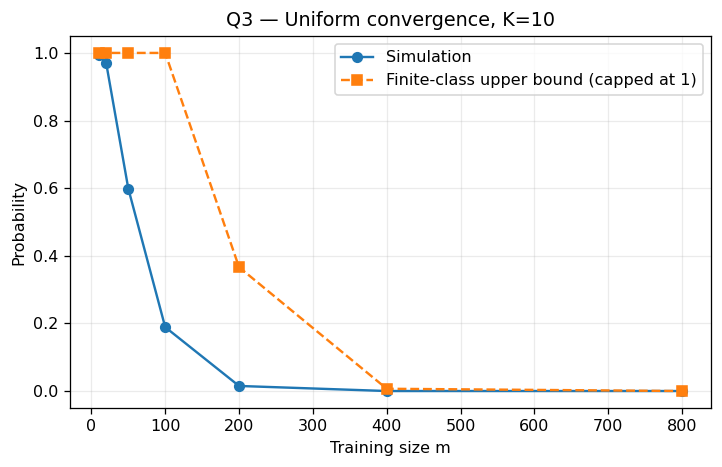

In [4]:
def estimate_uniform_failure(m, risks, repetitions=reps):
    errors = rng.binomial(m, np.asarray(risks)[None, :], size=(repetitions, len(risks)))
    delta_s = np.max(np.abs(errors/m - np.asarray(risks)[None, :]), axis=1)
    return np.mean(delta_s > epsilon)

K = 10
risks = np.linspace(0.10, 0.40, K)
uniform_fail = np.array([estimate_uniform_failure(m, risks) for m in m_values])
uniform_bound = 2*K*np.exp(-2*m_values*epsilon**2)
plt.plot(m_values, uniform_fail, 'o-', label='Simulation')
plt.plot(m_values, np.minimum(1,uniform_bound), 's--', label='Finite-class upper bound (capped at 1)')
plt.xlabel('Training size m');plt.ylabel('Probability');plt.title('Q3 — Uniform convergence, K=10')
plt.legend();plt.show()
for m, est, upper in zip(m_values,uniform_fail,uniform_bound):
    print(f'm={m:3d}: simulation={est:.3f}, bound={upper:.3f}')

**Interpretation — Q3.** To have uniform convergence, *every* hypothesis must have an empirical risk close to its true risk. This is more demanding than controlling one hypothesis. As the sample size increases, the probability that at least one hypothesis has a large deviation decreases.

## 4. Effect of the size of the hypothesis class
I repeat the same calculation with 5, 10, 50, 100 and 500 hypotheses. For a fair comparison, I keep the same range of true risks.

cell_14:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


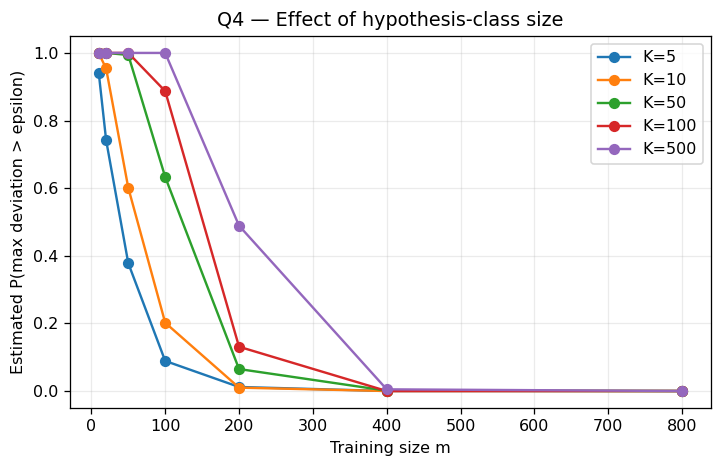

In [5]:
curves = {}
for K in K_values:
    risks = np.linspace(0.10, 0.40, K)
    curves[K] = np.array([estimate_uniform_failure(m, risks) for m in m_values])
    plt.plot(m_values, curves[K], marker='o', label=f'K={K}')
plt.xlabel('Training size m');plt.ylabel('Estimated P(max deviation > epsilon)')
plt.title('Q4 — Effect of hypothesis-class size');plt.legend();plt.show()

**Interpretation — Q4.** For a fixed sample size, the chance that at least one hypothesis deviates can increase with the number of hypotheses. So a larger class generally requires more data for uniform convergence. The sufficient sample-complexity formula grows with $\log K$, not linearly with $K$. Small Monte-Carlo fluctuations are normal.

## 5. Experimental sample complexity
I look for the smallest *tested* sample size where the estimated uniform-deviation probability is at most $\delta=0.05$. I compare it with the sufficient theoretical sample size $m\ge\log(2K/\delta)/(2\varepsilon^2)$. I use a finer sample-size grid here.

Smallest tested experimental m: 160
Theoretical sufficient m: 300
cell_17:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


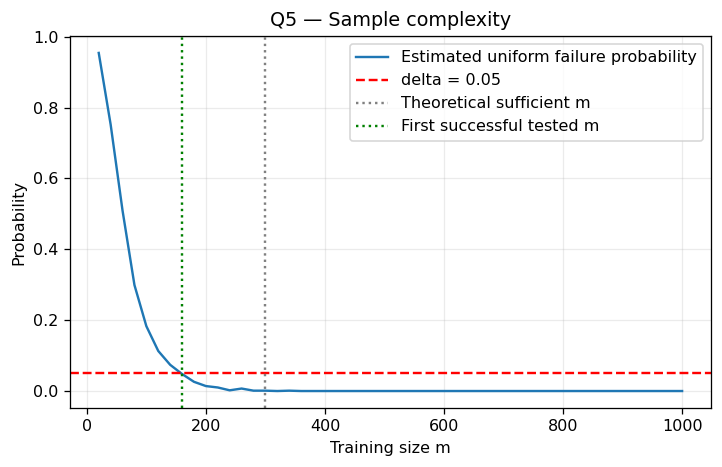

In [6]:
K = 10
risks = np.linspace(0.10,0.40,K)
m_grid = np.arange(20, 1001, 20)
prob_grid = np.array([estimate_uniform_failure(m,risks) for m in m_grid])
valid = m_grid[prob_grid <= delta]
experimental_m = int(valid[0]) if len(valid) else None
theoretical_m = int(np.ceil(np.log(2*K/delta)/(2*epsilon**2)))
print('Smallest tested experimental m:', experimental_m)
print('Theoretical sufficient m:', theoretical_m)
plt.plot(m_grid, prob_grid, label='Estimated uniform failure probability')
plt.axhline(delta, color='red', linestyle='--', label='delta = 0.05')
plt.axvline(theoretical_m, color='gray', linestyle=':', label='Theoretical sufficient m')
if experimental_m is not None:
    plt.axvline(experimental_m, color='green', linestyle=':', label='First successful tested m')
plt.xlabel('Training size m');plt.ylabel('Probability');plt.title('Q5 — Sample complexity')
plt.legend();plt.show()

**Interpretation — Q5.** The experimental value depends on the sample-size grid and on Monte-Carlo randomness. The theoretical formula is a sufficient condition: it guarantees control under the assumptions, but does not claim to give the smallest possible sample size. A simulation alone is not a formal proof of a $1-\delta$ guarantee.

# Part II — Simulating No-Free-Lunch
For each repetition, I generate a new random labeling of the finite domain $X=\{1,\ldots,N\}$. The learner memorizes labels of seen inputs and predicts a default value on unseen inputs. Training inputs are sampled *with replacement*, as required by $S\sim D^m$.

## 6. Seen and unseen inputs
For each $N$ and $m$, I compute the fraction of domain points never sampled. The theoretical expected fraction is $(1-1/N)^m$.

cell_21:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


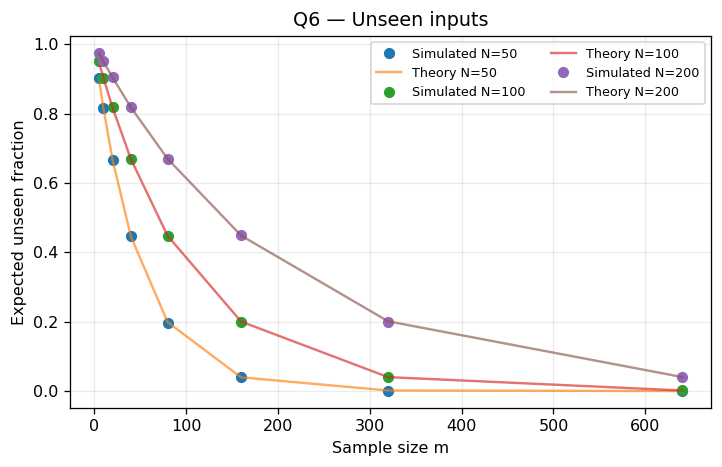

In [7]:
def unseen_fraction(N, m, repetitions=reps):
    values = np.empty(repetitions)
    for r in range(repetitions):
        # Draw a new random target as required, even though unseen count does not depend on labels.
        target = rng.integers(0, 2, size=N)
        drawn = rng.integers(0, N, size=m)
        values[r] = 1 - np.unique(drawn).size/N
    return values.mean()

m_nfl = np.array([5,10,20,40,80,160,320,640])
for N in [50,100,200]:
    simulations = [unseen_fraction(N,m) for m in m_nfl]
    theory = (1-1/N)**m_nfl
    plt.plot(m_nfl, simulations, 'o', label=f'Simulated N={N}')
    plt.plot(m_nfl, theory, '-', alpha=0.65, label=f'Theory N={N}')
plt.xlabel('Sample size m');plt.ylabel('Expected unseen fraction')
plt.title('Q6 — Unseen inputs');plt.legend(ncol=2, fontsize=8);plt.show()

**Interpretation — Q6.** The simulated unseen fraction closely follows the theoretical curve. For a fixed point, the probability that one draw misses it is $1-1/N$; all $m$ independent draws miss it with probability $(1-1/N)^m$. Averaging the unseen indicators over all points gives the same expected fraction (linearity of expectation).

## 7. Error on unseen inputs
A seen point is memorized correctly. An unseen point is predicted as 0 but has a new, independently random label, so its expected error is $1/2$. Consequently, the expected total risk is $\frac12(1-1/N)^m$.

cell_24:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
m=  5: simulated=0.4779, theory=0.4755
m= 10: simulated=0.4514, theory=0.4522
m= 20: simulated=0.4119, theory=0.4090
m= 40: simulated=0.3351, theory=0.3345
m= 80: simulated=0.2247, theory=0.2238
m=160: simulated=0.0997, theory=0.1001
m=320: simulated=0.0202, theory=0.0201
m=640: simulated=0.0008, theory=0.0008


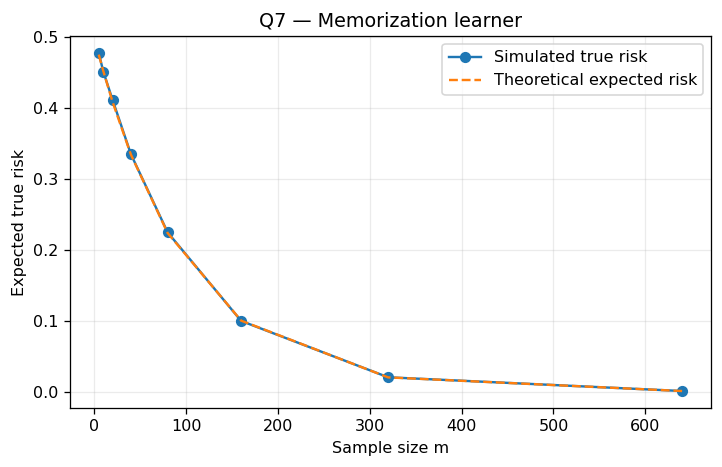

In [8]:
def random_target_experiment(N,m,rule='zero',repetitions=reps):
    scores = np.empty(repetitions)
    for r in range(repetitions):
        target = rng.integers(0,2,size=N)
        drawn = rng.integers(0,N,size=m)
        seen = np.zeros(N, dtype=bool);seen[drawn] = True
        pred = np.empty(N,dtype=int)
        pred[seen] = target[seen]
        if rule == 'zero': pred[~seen] = 0
        elif rule == 'one': pred[~seen] = 1
        elif rule == 'random': pred[~seen] = rng.integers(0,2,size=np.count_nonzero(~seen))
        else: raise ValueError('Unknown prediction rule')
        scores[r] = np.mean(pred != target)
    return scores.mean()

N = 100
nfl_risk = np.array([random_target_experiment(N,m) for m in m_nfl])
nfl_theory = 0.5*(1-1/N)**m_nfl
plt.plot(m_nfl,nfl_risk,'o-',label='Simulated true risk')
plt.plot(m_nfl,nfl_theory,'--',label='Theoretical expected risk')
plt.xlabel('Sample size m');plt.ylabel('Expected true risk');plt.title('Q7 — Memorization learner')
plt.legend();plt.show()
for m, sim, th in zip(m_nfl, nfl_risk, nfl_theory):
    print(f'm={m:3d}: simulated={sim:.4f}, theory={th:.4f}')

**Interpretation — Q7.** The expected error is about half of the unseen fraction. The learner cannot infer completely random labels for inputs it has not observed. Risk decreases only because more points are eventually seen and memorized.

## 8. Changing the prediction on unseen inputs
I compare three rules: always predict 0, always predict 1, or randomly predict 0 or 1. Each is expected to have error $1/2$ on unseen points for independently random targets.

cell_27:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


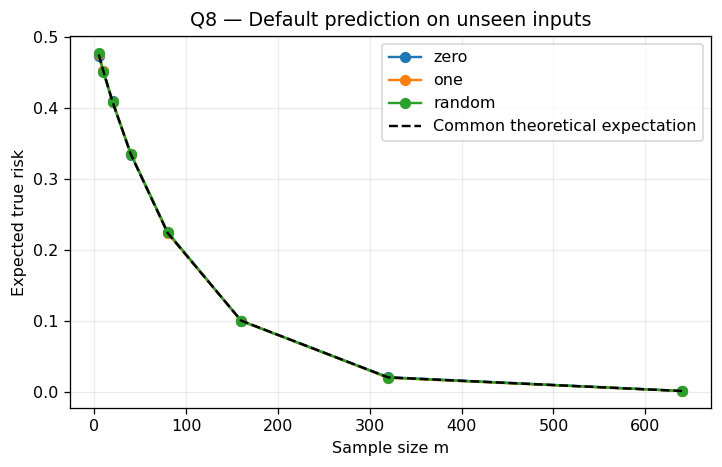

In [9]:
for rule in ['zero','one','random']:
    risk = [random_target_experiment(N,m,rule=rule) for m in m_nfl]
    plt.plot(m_nfl,risk,marker='o',label=rule)
plt.plot(m_nfl,nfl_theory,'k--',label='Common theoretical expectation')
plt.xlabel('Sample size m');plt.ylabel('Expected true risk');plt.title('Q8 — Default prediction on unseen inputs')
plt.legend();plt.show()

**Interpretation — Q8.** The three approaches give similar average risks. None has a consistent advantage over the others across random target functions. This illustrates the No-Free-Lunch idea: without assumptions about the target, the labels of unseen inputs cannot be predicted better than chance on average.

# Part III — Introducing Prior Knowledge
Now I replace arbitrary random labels with a **structured target** $f_\theta(x)=\mathbf{1}[x>\theta]$, where $\theta\in\{1,\ldots,N-1\}$. I train a threshold hypothesis using ERM, then calculate its true risk over the entire domain.

## 9. Learning with a matching inductive bias
I check all thresholds $t\in\{1,\ldots,N-1\}$ and choose one minimizing the training error. This is exact ERM in the requested hypothesis class, implemented without scikit-learn.

m=  5: mean threshold learner risk=0.1410
m= 10: mean threshold learner risk=0.0797
m= 20: mean threshold learner risk=0.0405
m= 40: mean threshold learner risk=0.0200
m= 80: mean threshold learner risk=0.0074
m=160: mean threshold learner risk=0.0026
m=320: mean threshold learner risk=0.0003
m=640: mean threshold learner risk=0.0000
cell_31:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


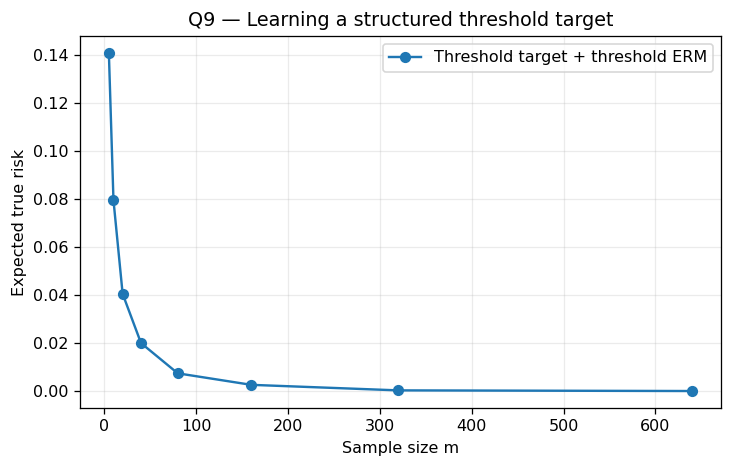

In [10]:
def threshold_erm(sample_x, sample_y, N):
    # Counts of labels 0 and 1 at each point of the domain
    zeros = np.bincount(sample_x[sample_y == 0], minlength=N+1)
    ones  = np.bincount(sample_x[sample_y == 1], minlength=N+1)
    # For threshold t, predict 0 for x<=t and 1 for x>t
    # Mistakes = label 1 on left + label 0 on right
    left_ones = np.cumsum(ones)
    right_zeros = zeros.sum() - np.cumsum(zeros)
    losses = left_ones[1:N] + right_zeros[1:N]
    return int(np.argmin(losses) + 1)

def threshold_experiment(N,m,repetitions=reps):
    scores = np.empty(repetitions)
    grid = np.arange(1,N+1)
    for r in range(repetitions):
        theta = int(rng.integers(1,N))
        sample_x = rng.integers(1,N+1,size=m)
        sample_y = (sample_x > theta).astype(int)
        chosen = threshold_erm(sample_x,sample_y,N)
        scores[r] = np.mean((grid > chosen) != (grid > theta))
    return scores.mean()

structured_risk = np.array([threshold_experiment(N,m) for m in m_nfl])
for m, sim in zip(m_nfl,structured_risk):
    print(f'm={m:3d}: mean threshold learner risk={sim:.4f}')
plt.plot(m_nfl,structured_risk,'o-',label='Threshold target + threshold ERM')
plt.xlabel('Sample size m');plt.ylabel('Expected true risk')
plt.title('Q9 — Learning a structured threshold target');plt.legend();plt.show()

**Interpretation — Q9.** When the true labels follow a threshold, the learner can generalize from seen inputs to unseen points, because the hypothesis class matches the structure of the target. The mean risk should decrease with more data.

## 10. Random targets vs structured targets
I compare the two expected risks using the same finite domain and sample sizes. The crucial difference is the assumption about the target labeling.

cell_34:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
m | random target | structured target
  5 | 0.4779        | 0.1410
 10 | 0.4514        | 0.0797
 20 | 0.4119        | 0.0405
 40 | 0.3351        | 0.0200
 80 | 0.2247        | 0.0074
160 | 0.0997        | 0.0026
320 | 0.0202        | 0.0003
640 | 0.0008        | 0.0000


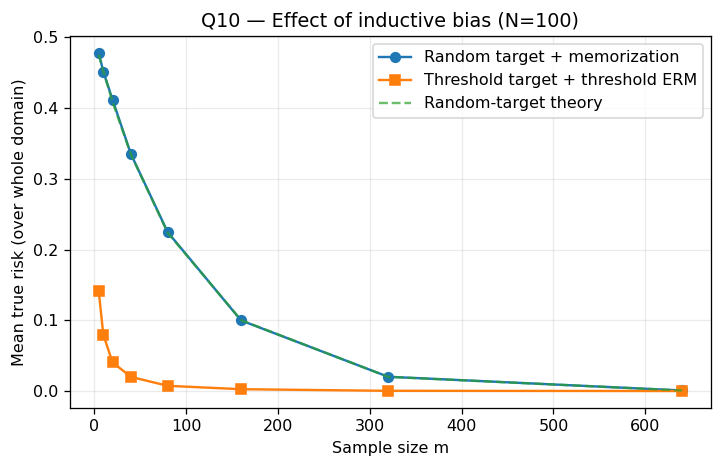

In [11]:
plt.plot(m_nfl,nfl_risk,'o-',label='Random target + memorization')
plt.plot(m_nfl,structured_risk,'s-',label='Threshold target + threshold ERM')
plt.plot(m_nfl,nfl_theory,'--',alpha=0.7,label='Random-target theory')
plt.xlabel('Sample size m');plt.ylabel('Mean true risk (over whole domain)')
plt.title('Q10 — Effect of inductive bias (N=100)');plt.legend();plt.show()
print('m | random target | structured target')
for m,a,b in zip(m_nfl,nfl_risk,structured_risk):
    print(f'{m:3d} | {a:.4f}        | {b:.4f}')

**Interpretation — Q10.** With random targets, memorization does not tell us the correct labels at unseen inputs. With threshold targets, the ordering of input points contains useful information: observing a few labeled examples helps locate the boundary. The threshold assumption is an **inductive bias**, and it makes learning from limited data possible in this setting.

## 11. Final analysis and conclusion

In this homework, I observed that the empirical risk of one hypothesis becomes more concentrated around its true risk when I increase the training size. When I consider all hypotheses at the same time, I need to control the largest deviation. This becomes more difficult when the hypothesis class gets larger. I also saw that Hoeffding's inequality and the finite-class bound can be conservative because they give upper guarantees, not exact probabilities.

In the No-Free-Lunch experiments, the labels were completely random. For unseen points, predicting 0, predicting 1, and predicting randomly had almost the same expected error. This happens because the training sample contains no information about arbitrary unseen labels.

Finally, when I replaced random targets with threshold functions, the learner could use the known structure of the problem. ERM over thresholds was able to predict labels on unseen inputs much more effectively. I learned that **having more examples matters, but the assumptions we make about the problem also matter**.

**Before submission:** After running the notebook, verify the numbers in the Q5 and Q10 output and add two concrete observations in your own words (for example the experimental sample size at which the uniform failure rate first falls below 0.05, and a comparison of the two risks at $m=20$).